# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/unatisaini/flyrank-internship-mi/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

*The research question and the decision it supports.*

Teams that manage many pages must decide where to spend limited review time. Pages that already rank and earn impressions but attract few clicks are cheap to improve, since a better title or description may help without new content. The decision this work supports is: which pages should get a metadata or content review first?

## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

We used the pseudonymized engagement_fix example cut of the FlyRank ML Internship dataset: 33,202 page rows with 30-day impressions, clicks, CTR, average position, site-engagement measures and content tiers. We dropped 358 rows with no CTR or position, then kept pages with at least 100 impressions to avoid noisy CTRs, leaving 28,078 rows. After label construction, 26,375 pages from 38 clients were scored. Client IDs are hashed and no client names, domains, URLs or queries appear in this paper. Nearly all pages (99.6%) share one content type, so content type carries little signal in this sample.

## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

Label. Pages were grouped into position bands (1-3, 3-5, 5-7, 7-10, 10-15, 15-20, 20-30, 30+). The expected CTR of a band is its median CTR, computed on training folds only. A page is an under-performer if its CTR is below 50% of that expected value.

Features. Average position, log impressions, engagement rate, scroll rate, AI-traffic share, and content, age, freshness and length tiers. We excluded CTR, clicks and every rule flag that was derived from them, because they would leak the label. We also excluded sessions, users and pageviews from the headline model, since they track clicks closely (see Limitations).

Validation. 5-fold GroupKFold by client, so no client appears in both training and test data. We used a histogram gradient-boosting classifier (depth 4, 200 iterations) and measured PR-AUC and precision@50 per fold.

Baselines. Two rule rankings on the same folds: R1 ranks by impressions, and R2 ranks by the dataset's own needs_ctr_fix flag (ties broken by impressions).

## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

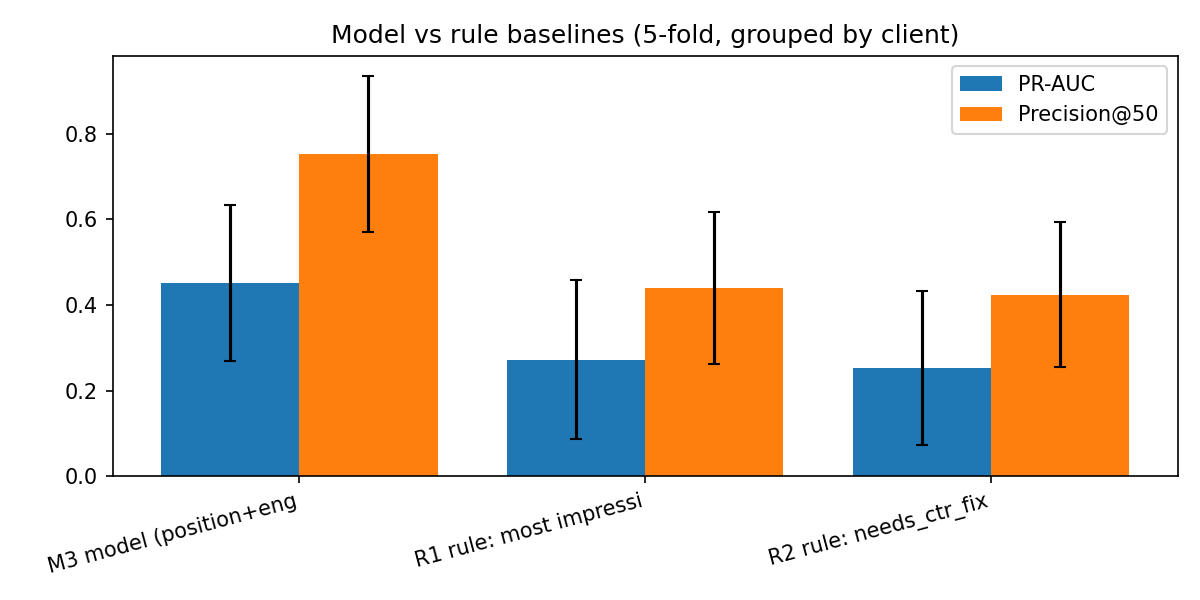

Figure 1. Model vs rule baselines on held-out clients (mean ± std over 5 folds).

The model reached a mean PR-AUC of 0.451 (R1: 0.272, R2: 0.252) and a mean precision@50 of 0.752 (R1: 0.440, R2: 0.424), and it won on precision@50 in 5 of 5 folds. The spread between folds is large (std about 0.18) because clients differ greatly in size and mix, so the ordering is consistent but the exact lift is uncertain. A position-and-impressions-only model scored PR-AUC 0.421, which means engagement features add a modest gain, while content features added none.

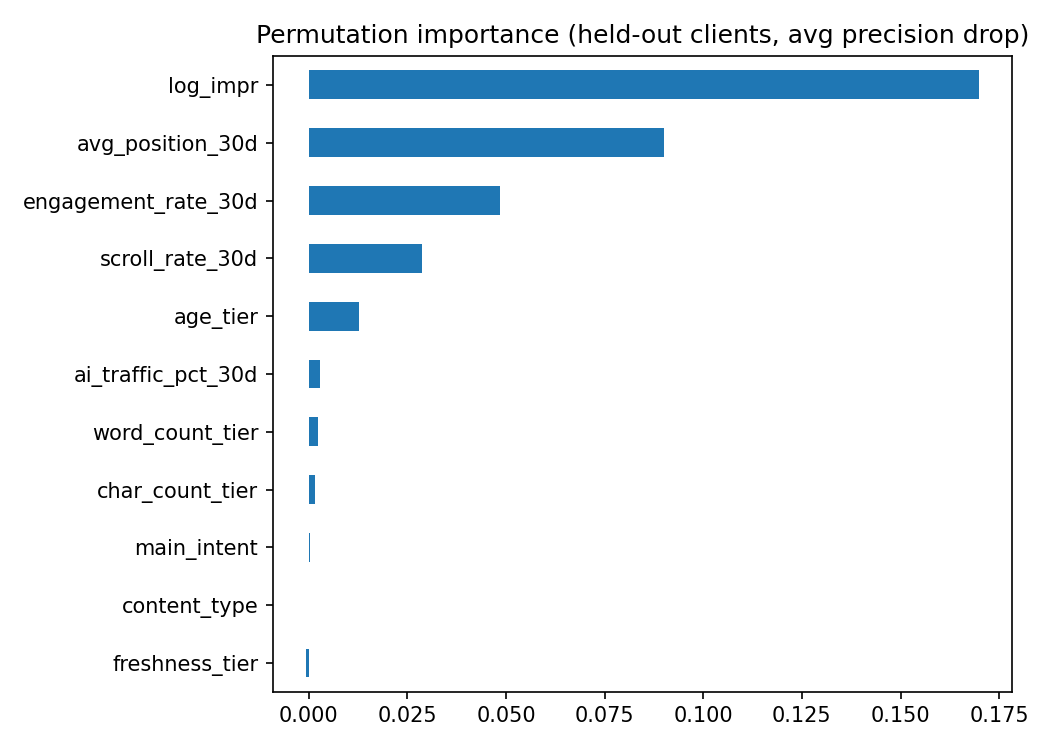

Figure 2. Permutation importance on held-out clients.

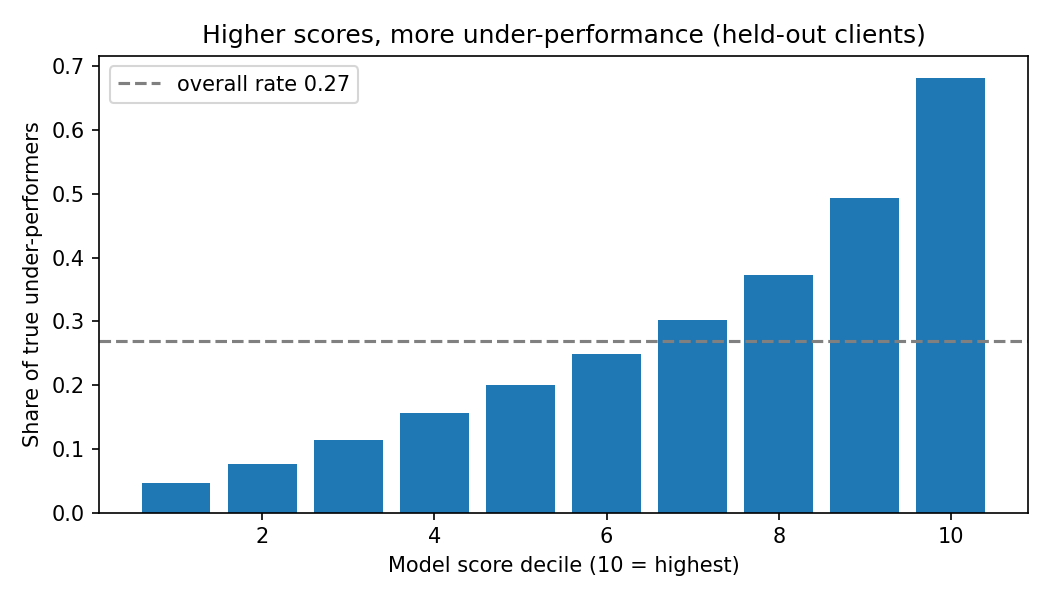

Figure 3. Share of true under-performers by model-score decile.

The share of true under-performers rises steadily from 4.6% in the lowest-scored decile to 68.2% in the highest, about 2.5 times the overall rate of 26.9%.

## 5. Limitations

*What this work cannot claim.*

Observational, not causal. The data cover a single 30-day window. We show association only and make no claim about how Google ranks pages or about the effect of any change.

Peer-relative label. "Under-performer" means below half the typical CTR for similar positions in this sample. It is a prioritisation proxy and not an absolute standard.

Average position hides query mix. Expected CTR did not fall smoothly with position, which suggests query and snippet effects that this data cannot separate.

Client imbalance. The largest client holds 32% of scored pages and fold results vary widely, so the lift estimate is imprecise.

Proxy leakage. Adding sessions, users and pageviews raised PR-AUC to 0.573, but these measures track clicks closely, so we report this as a sensitivity check and not as a result.

Narrow content mix and example cut. Nearly all pages are one content type, and the data are a pseudonymized example cut and not the full warehouse.

## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

The table lists the 20 highest-priority pages, capped at 3 per client for diversity. Priority is the model score multiplied by estimated missed clicks, where missed clicks = (expected CTR − actual CTR) × impressions for the window, an estimate for ordering only. Among these 20 pages, 85% were true under-performers on held-out clients. Impressions and missed clicks are rounded and no identifiers are shown.



#	Avg position	Impressions (≈)	CTR %	Expected CTR %	Model score	Est. missed clicks (≈)	Reason codes	Suggested action
1	6.8	234000	0.02	0.57	0.77	1290	STRIKING_LOW_CTR|HIGH_VISIBILITY|ZERO_ENGAGEMENT	Rewrite title/meta, check intent match
2	7.4	177000	0.02	0.35	0.92	590	STRIKING_LOW_CTR|HIGH_VISIBILITY	Rewrite title/meta, check intent match
3	6.4	522000	0.29	0.46	0.60	890	STRIKING_LOW_CTR|HIGH_VISIBILITY	Rewrite title/meta, check intent match
4	8.7	115000	0.01	0.48	0.96	540	STRIKING_LOW_CTR|HIGH_VISIBILITY|ZERO_ENGAGEMENT	Rewrite title/meta, check intent match
5	7.1	120000	0.03	0.48	0.93	540	STRIKING_LOW_CTR|HIGH_VISIBILITY|ZERO_ENGAGEMENT	Rewrite title/meta, check intent match
6	5.0	276000	0.16	0.61	0.32	1240	TOP5_LOW_CTR|HIGH_VISIBILITY	Review title/meta (snippet)
7	2.1	497000	0.55	0.77	0.32	1090	TOP5_LOW_CTR|HIGH_VISIBILITY	Review title/meta (snippet)
8	8.4	160000	0.02	0.33	0.71	500	STRIKING_LOW_CTR|HIGH_VISIBILITY	Rewrite title/meta, check intent match
9	5.3	145000	0.11	0.46	0.57	510	STRIKING_LOW_CTR|HIGH_VISIBILITY	Rewrite title/meta, check intent match
10	6.4	102000	0.09	0.46	0.75	380	STRIKING_LOW_CTR|HIGH_VISIBILITY	Rewrite title/meta, check intent match
11	10.2	104000	0.01	0.32	0.85	320	LOWER_RANK_LOW_CTR|HIGH_VISIBILITY	Content review, then monitor
12	20.2	95000	0.02	0.30	0.96	270	LOWER_RANK_LOW_CTR|HIGH_VISIBILITY|ZERO_ENGAGEMENT	Content review, then monitor
13	1.1	106000	0.02	0.72	0.34	740	TOP5_LOW_CTR|HIGH_VISIBILITY	Review title/meta (snippet)
14	8.7	106000	0.03	0.33	0.77	320	STRIKING_LOW_CTR|HIGH_VISIBILITY	Rewrite title/meta, check intent match
15	25.7	60000	0.05	0.30	0.98	150	LOWER_RANK_LOW_CTR|HIGH_VISIBILITY|ZERO_ENGAGEMENT	Content review, then monitor
16	6.0	53000	0.14	0.44	0.76	160	STRIKING_LOW_CTR|HIGH_VISIBILITY|ZERO_ENGAGEMENT	Rewrite title/meta, check intent match
17	6.7	116000	0.31	0.44	0.75	150	STRIKING_LOW_CTR|HIGH_VISIBILITY	Rewrite title/meta, check intent match
18	9.0	48000	0.05	0.33	0.82	130	STRIKING_LOW_CTR|HIGH_VISIBILITY	Rewrite title/meta, check intent match
19	6.3	41000	0.05	0.44	0.67	160	STRIKING_LOW_CTR|HIGH_VISIBILITY	Rewrite title/meta, check intent match
20	5.6	50000	0.20	0.44	0.85	120	STRIKING_LOW_CTR|HIGH_VISIBILITY|ZERO_ENGAGEMENT	Rewrite title/meta, check intent match


Playbook. TOP5_LOW_CTR: review the title and meta description (snippet). STRIKING_LOW_CTR (position 5-10): rewrite the title and meta, and check intent match. LOWER_RANK_LOW_CTR: run a content review, then monitor. HIGH_VISIBILITY marks the top quartile by impressions, so fixes there pay off most, and ZERO_ENGAGEMENT marks pages where engaged sessions are zero. Re-measure after any change, and treat the scores as a reviewing order, not a verdict.

## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

The full code is in the notebook work/w08_capstone.ipynb of the repository github.com/unatisaini/flyrank-internship-ml. Settings are random_state=42, GroupKFold(5) and a minimum of 100 impressions. The dataset needs gated access on Hugging Face and is not included here.

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
